# AP 155 Lab Exercise
---
## Exercise 9: Minimization

_Instructions_: 
- **Problem 1**
    - Figure: Generate a $1\times2$ showing the two functions and minima markings solved using golden-search
    - Discussion: What happens if a number other than the golden ratio is used to perform the golden section search algorithm? What did you have to do to obtain the maximum?
- **Problem 2**
    - Figure: Plot of $U$ vs $N$ (for a minimum of 20 $N$ points). Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - Discussion: In a single sentence, describe what gradient descent does. How does the parameter $\gamma$ matter? 
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Pasion, Kyla Zarina
- _Student No._: 2024-09224
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Local extrema of $\phi(x)$ and corresponding zero-crossings of the first derivative $\phi'(x)$](./Figures/e9_figure0.png)

**Figure 1.** Local extrema of $\phi(x)$ and corresponding zero-crossings of the first derivative $\phi'(x)$

![Synthetic data interpolation](./Figures/e9_figure1.png)

**Figure 2.** Comparison of electrostatic potential energy $U$ calculated via gradient descent against theoretical Thomson values for $N \in [2, 60]$

![Synthetic data interpolation](./Figures/e9_figure2.png)

**Figure 3.** Optimal spatial configuration of $N=60$ constrained point charges minimizing electrostatic potential


### Report discussion

**Problem 1: Min-maxxing with golden-search** 

The Golden-Section Search algorithm successfully isolated the local extrema of the polynomial $\phi(x)$ within the domain $x \in [0, 5]$. By iteratively narrowing the bracketed intervals using the golden ratio, the algorithm identified local minima at coordinates $(0.750, -3.418)$ and $(4.000, -12.000)$, alongside a local maximum at $(2.000, 0.000)$. Evaluating the analytical first derivative $\phi'(x)$ at these specific points yields exactly zero. This confirms that the stationary points computed via the numerical search correspond directly to the zero-crossings visualized on the derivative plot, validating the numerical algorithm's accuracy in locating critical points.

**Problem 2. Thomson problem with gradient descent**
Minimizing the total electrostatic potential energy $U(N)$ of constrained charges on a unit sphere via gradient descent yielded results that closely track the theoretical Thomson values for $N=2$ through $N=60$. Utilizing a scaled learning rate of $\gamma = 1/N$ effectively stabilized the optimization against the quadratically increasing number of pairwise interactions. While absolute errors remained minimal (typically $<10^{-1}$), slight deviations at higher $N$ values reflect the gradient descent algorithm occasionally converging into local, rather than global, energy minima. For the specific $N=60$ system, the optimized spatial distribution forms a highly symmetric, fullerene-like spherical shell. This geometric arrangement maximizes inter-particle distances across the surface, effectively minimizing Coulombic repulsion to reach a stable net electrostatic energy of approximately $U \approx 1543.83$.
### Other comments
None


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from math import sqrt

rng = np.random.default_rng(24601)

### Problem 1: Min-maxxing with golden-search

Consider the following equation,

$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4. \tag{1}
$$

- Plot $\phi$ across some domain $x$ (you choose the domain). Visually inspect the plot and record initial estimates for all local minima and local maxima within the interval.
- Implement the Golden-Section Search algorithm (see Section $3$, you may copy it into your code below) to find function minima within a given bracket $[a, b]$ to a specified tolerance. Use your algorithm to locate the precise coordinates $(x^*, \phi(x^*))$ of all local minima and local maxima of Eq. $(1)$.
- **[REPORT FIGURE 1]** Generate a single figure containing a $1 \times 2$ array of subplots:
    - Left Subplot: Plot $\phi(x)$ versus $x$. Overlay and label all identified local minima and maxima using distinct markers.
    - Right Subplot: Plot the analytical first derivative $\phi'(x)$ versus $x$. Mark the zero-crossing points that correspond to the extrema found on the left plot.

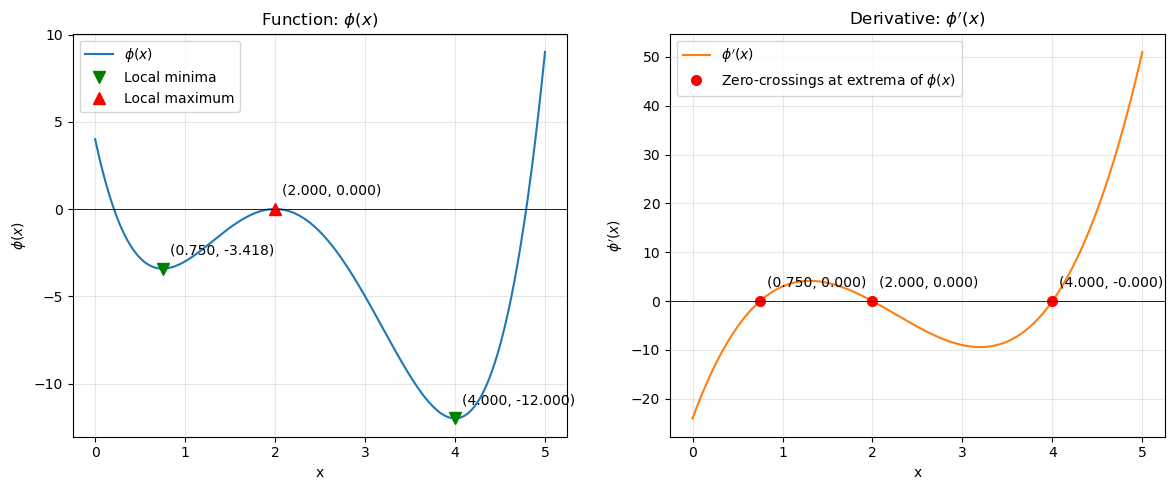

In [2]:
# Evaluate the polynomial
def phi_x(x):
    return x**4 - 9*x**3 + 25*x**2 - 24*x + 4

# Evaluate the analytical first derivative
def dphi_x(x):
    return 4*x**3 - 27*x**2 + 50*x - 24

# Golden-section search for finding a local minimum
def golden(phi_x, x0, x1, kmax=200, tol=1.e-8):
    """Find the minimum of a unimodal function within [x0, x1]."""
    varphi = 0.5 * (1 + sqrt(5))

    for k in range(1, kmax + 1):
        # Calculate two interior points using the golden ratio
        x2 = x0 + (x1 - x0) / (varphi + 1)
        x3 = x0 + (x1 - x0) * varphi / (varphi + 1)

        # Retain the interval containing the minimum
        if phi_x(x3) < phi_x(x2):
            x0 = x2
        else:
            x1 = x3

        # Stop when the interval is sufficiently small
        if abs(x1 - x0) < tol:
            return (x0 + x1) / 2

    # Return None if the tolerance was not reached
    return None

# Find a maximum by minimizing the negative function
def golden_max(phi_x, x0, x1, kmax=200, tol=1.e-8):
    """Find a local maximum within [x0, x1]."""
    return golden(
        lambda x: -phi_x(x), x0, x1, kmax=kmax, tol=tol)

# Locate all local extrema using brackets around each extremum
phi_min = np.array([
    golden(phi_x, 0.0, 1.5),
    golden(phi_x, 3.0, 5.0)
    ])

phi_max = np.array([
    golden_max(phi_x, 1.0, 3.0)
    ])

xp = np.linspace(0, 5, 400)

plt.figure(figsize=(12, 5))

# Left subplot: polynomial and its extrema
plt.subplot(1, 2, 1)
plt.plot(xp, phi_x(xp), color="tab:blue", label=r"$\phi(x)$")
plt.plot(phi_min, phi_x(phi_min), "gv", markersize=9, label="Local minima")
plt.plot(phi_max, phi_x(phi_max), "r^", markersize=9, label="Local maximum")

for x in phi_min:
    plt.annotate(
        f"({x:.3f}, {phi_x(x):.3f})",
        (x, phi_x(x)),
        xytext=(5, 10),
        textcoords="offset points")

for x in phi_max:
    plt.annotate(
        f"({x:.3f}, {phi_x(x):.3f})",
        (x, phi_x(x)),
        xytext=(5, 10),
        textcoords="offset points")

plt.title(r"Function: $\phi(x)$")
plt.axhline(0, color="black", linewidth=0.6)
plt.xlabel("x")
plt.ylabel(r"$\phi(x)$")
plt.grid(alpha=0.3)
plt.legend()

# Right subplot: analytical first derivative
plt.subplot(1, 2, 2)
plt.plot(xp, dphi_x(xp), color="tab:orange", label=r"$\phi'(x)$")

# Mark the extrema of the original polynomial
x_extrema = np.concatenate((phi_min, phi_max))
plt.plot(
    x_extrema,
    dphi_x(x_extrema),
    "ro",
    markersize=7,
    label="Zero-crossings at extrema of $\phi(x)$")

for x in x_extrema:
    plt.annotate(
        f"({x:.3f}, {dphi_x(x):.3f})",
        (x, dphi_x(x)),
        xytext=(5, 10),
        textcoords="offset points")

plt.title(r"Derivative: $\phi'(x)$")
plt.axhline(0, color="black", linewidth=0.6)
plt.xlabel("x")
plt.ylabel(r"$\phi'(x)$")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("Figures/e9_figure0", dpi=300)
plt.tight_layout()
plt.show()


#### Problem 1 code summary

The script uses golden-section search to locate the local minima and maximum of the polynomial within brackets estimated from visual inspection. It then plots the polynomial and its analytical first derivative in a single figure, marking the extrema and their corresponding derivative zero-crossings.

---
### Problem 2: Thomson problem with gradient descent ([Wikipedia link](https://en.wikipedia.org/wiki/Thomson_problem))

The goal of the Thomson problem is to determine the minimum electrostatic potential energy configuration given $N$ electrons constrained to the surface of a unit sphere. The electrons repel each other with a force given by Coulomb's law. The total electrostatic potential energy of each $N$-electron configuration may then be expressed as the sum of all pair-wise interaction energies:
$$ U(N) = \sum_{i<j} \frac{1}{r_{ij}}. \tag{2}$$
In context of minimization, we call Eq. $(2)$ our **cost function** or **loss function**. Here, we use simplified units of $e=1$ and $k=1/4\pi\epsilon_0=1$ (the Coulomb constant) without loss of generality.

- Complete the codes below. Add docstrings and comments to all functions.
- Create a 1D array `sphe_params` of initial particle positions in spherical coordinates (random $\theta$, $\phi$, BUT constrained to the surface of a unit sphere i.e. $r=1$).
- Minimize loss function $U(N)$ using gradient descent and `sphe_params` as your initial guess (see Section 3, you may the codes `termcrit`, `gradient`, and `descent` into your code below). Your output should be a 1D array similar to `sphe_params` but the positions that minimizes the potential.
- **[REPORT FIGURE 2]** Plot of $U$ vs $N$. Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - (Optional) Use 3D plotting in Matplotlib to show the geometry for $N=60$ configuration. What does it look like? What is its corresponding net electrostatic potential?

In [3]:
def termcrit(xolds,xnews):
    """ Compares the old parameter values with the new parameter
    values after one gradient descent step """
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def gradient(phi,xs,h=1.e-6):
    """ Estimates the gradient numerically using the forward 
    finite-difference method """
    # Evaluate the cost function at the current parameters
    phi0 = phi(xs)
    grad = np.zeros_like(xs, dtype=float)
    for i in range(xs.size):
        xs_perturbed = xs.copy()
        xs_perturbed[i] += h
        
        grad[i] = (phi(xs_perturbed) - phi0) / h

    return grad

def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    """ Repeatedly updates the angular coordinates to lower the energy """
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews

In [4]:
def spherical_to_cartesian(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)
    
    returns Nx3 array of particle positions in cartesian coords
    """
    N = len(sphe_params) // 2
    thetas = sphe_params[:N]
    phis = sphe_params[N:]

    # Convert spherical coordinates into Cartesian coordinates
    x = R0 * np.sin(thetas) * np.cos(phis)
    y = R0 * np.sin(thetas) * np.sin(phis) 
    z = R0 * np.cos(thetas) 
    
    return np.column_stack((x, y, z))


def compute_dist(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns distance matrix where ij is the distance between ith and jth particle
    """
    pos = spherical_to_cartesian(sphe_params, R0)
    diff = pos[:, np.newaxis, :] - pos[np.newaxis, :, :]
    dist_matrix = np.linalg.norm(diff, axis=-1)
    return dist_matrix

def electrostatic_potential(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns total electrostatic potential
    """
  
    if sphe_params.ndim == 2:
        return np.array([electrostatic_potential(sphe_params[:, j], R0) for j in range(sphe_params.shape[1])])

    d_matrix = compute_dist(sphe_params, R0)

    N_local = len(sphe_params) // 2
    i_upper, j_upper = np.triu_indices(N_local, k=1)
    distances = d_matrix[i_upper, j_upper]
        
    return np.sum(1.0 / distances)

In [5]:
# COMPLETE THIS CODE BLOCK

rng = np.random.default_rng(24601)

N =  60 # number of particles (minimum of 2)

# theoretical list of potential energies from N=2 to N=60
u_thom = [
    0.500000000, 1.732050808, 3.674234614, 6.474691495, 9.985281374,
    14.452977414, 19.675287861, 25.759986531, 32.716949460, 40.596450510,
    49.165253058, 58.853230612, 69.306363297, 80.670244114, 92.911655302,
    106.050404829, 120.084467447, 135.089467557, 150.881568334, 167.641622399,
    185.287536149, 203.930190663, 223.347074052, 243.812760299, 265.133326317,
    287.302615033, 310.491542358, 334.634439920, 359.603945904, 385.530838063,
    412.261274651, 440.204057448, 468.904853281, 498.569872491, 529.122408375,
    560.618887731, 593.038503566, 626.389009017, 660.675278835, 695.916744342,
    732.078107544, 769.190846459, 807.174263085, 846.188401061, 886.167113639,
    927.059270680, 968.713455344, 1011.557182654, 1055.182314726, 1099.819290319,
    1145.418964319, 1191.922290416, 1239.361474729, 1287.772720783, 1337.094945276,
    1387.383229253, 1438.618250640, 1490.773335279, 1543.830400976
]

init_theta = rng.uniform(0, np.pi, N)    # using rng, generate N random data points between 0 and pi
init_phi = rng.uniform(0, 2*np.pi, N)     # using rng, generate N random data points between 0 and 2pi

xolds = np.hstack((init_theta, init_phi)) # this is the 1d array where the first half is the thetas and 2nd half is the phis

xnews = descent(electrostatic_potential, gradient, xolds, gamma=1/N, kmax=2000)
# use descent function and xolds to calculate the positions that minimizes the cost function
# you may need to test different gamma values (test diff values with your classmates to see which values are closest to theo)

min_potential = electrostatic_potential(xnews) # calculate the "minimized" U given optimized positions
print(f"N = {N}: U_initial = {electrostatic_potential(xolds):.9f}, "f"U_descent = {min_potential:.9f}, U_thom = {u_thom[N-2]:.9f}")

Reached max iterations (2000).
N = 60: U_initial = 1855.573161725, U_descent = 1661.270472573, U_thom = 1543.830400976


Converged at iteration 363
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max iterations (2000).
Reached max 

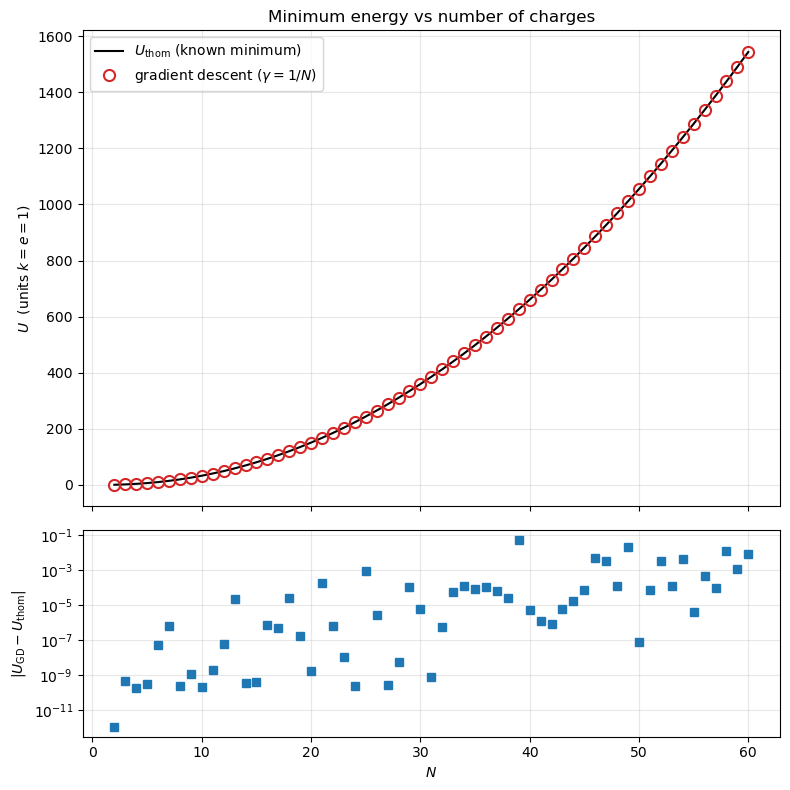

In [6]:
# from N=2 up to 20 (or more), generate the optmized positions and calculate the corresponding minimized potential energies
# for each N, always initialize a random array of positions of N particles 

N_list = np.arange(2, 61) #N list
U_gd = np.zeros(N_list.size) #array for minimized energy

for idx, n in enumerate(N_list): 
    x0 = np.hstack((rng.uniform(0, np.pi, n), rng.uniform(0, 2*np.pi, n)))
    xopt = descent(electrostatic_potential, gradient, x0, gamma=1/n, kmax=2000)
    U_gd[idx] = electrostatic_potential(xopt)

U_th = np.array(u_thom[:N_list.size])       
abs_err = np.abs(U_gd - U_th)  

print("  N    U (gradient descent)    U (Thomson)    abs. error")
for i in range(len(N_list)):
    print(f"{N_list[i]:3d}    {U_gd[i]:18.9f}    {U_th[i]:13.9f}    {abs_err[i]:.2e}")



fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True,
                        gridspec_kw={'height_ratios': [3, 1.3]})

axs[0].plot(N_list, U_th, '-', c='k', lw=1.5, label=r'$U_\mathrm{thom}$ (known minimum)')
axs[0].plot(N_list, U_gd, 'o', c='tab:red', mfc='none', ms=8, mew=1.5,
            label=r'gradient descent ($\gamma = 1/N$)')
axs[0].set_ylabel(r'$U$  (units $k=e=1$)')
axs[0].set_title('Minimum energy vs number of charges')
axs[0].legend()
axs[0].grid(alpha=0.3)

axs[1].semilogy(N_list, np.maximum(abs_err, 1e-12), 's', c='tab:blue')
axs[1].set_xlabel(r'$N$')
axs[1].set_ylabel(r'$|U_\mathrm{GD} - U_\mathrm{thom}|$')
axs[1].grid(alpha=0.3, which='both')

fig.tight_layout()
plt.savefig("Figures/e9_figure1", dpi=300)
plt.show()

Reached max iterations (3000).
N = 60: U_descent = 1543.830767, U_thom = 1543.830401


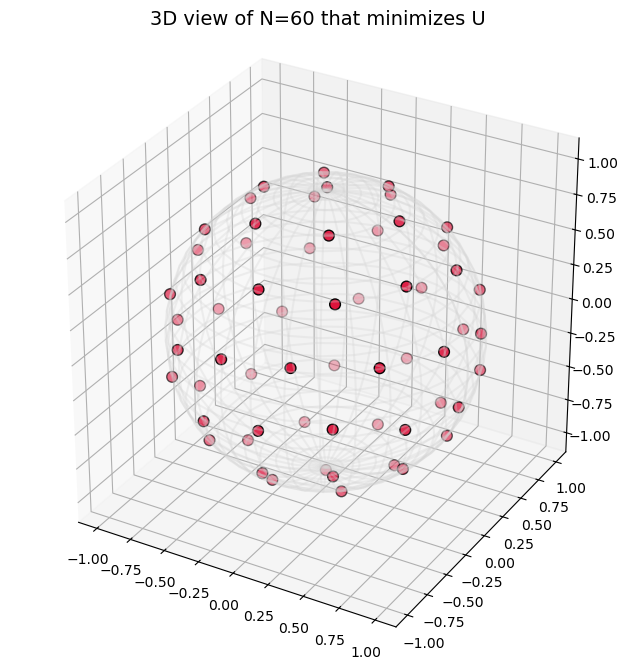

In [7]:
# OPTIONAL
# for 3d plotting of N=60 (it might take a minute to process)

N = 60
init_theta = rng.uniform(0, np.pi, N)
init_phi = rng.uniform(0, 2*np.pi, N) 
xolds = np.hstack((init_theta, init_phi))
xnews = descent(electrostatic_potential, gradient, xolds, gamma=1/N, kmax=3000) 

U60 = electrostatic_potential(xnews)
print(f"N = 60: U_descent = {U60:.6f}, U_thom = {u_thom[N-2]:.6f}")

pos = spherical_to_cartesian(xnews)


fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

u = np.linspace(0, 2 * np.pi, 30)
v = np.linspace(0, np.pi, 30)
x_sp = np.outer(np.cos(u), np.sin(v))
y_sp = np.outer(np.sin(u), np.sin(v))
z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(x_sp, y_sp, z_sp, color='lightgrey', alpha=0.3)

ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color='crimson', s=60, edgecolors='k', depthshade=True)

ax.set_box_aspect([1, 1, 1])
ax.set_title('3D view of N=60 that minimizes U', fontsize=14)
plt.savefig("Figures/e9_figure2", dpi=300)
plt.show()

#### Problem 2 code summary

This code solves the Thomson problem by minimizing the electrostatic potential energy of N electrons on a unit sphere using gradient descent and finite-difference gradients. Spherical coordinates keep the electrons on the sphere, while the convergence criterion tracks changes between iterations to determine when the solution has stabilized.

---
## Section 3: Notes

In [8]:
import numpy as np
import matplotlib.pyplot as plt

### Golden search (minimization tool)

In [9]:
from math import sqrt

def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + sqrt(5))
    
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
    
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
    
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew

#### Example: 

The Buckingham potential is an approximate representation of the potential
energy of interaction between atoms in a solid or gas as a function of the distance $r$ between them:
$$ V(r) = V_0 \left[\left(\frac{\sigma}{r}\right)^6 - e^{-r/\sigma}\right].$$

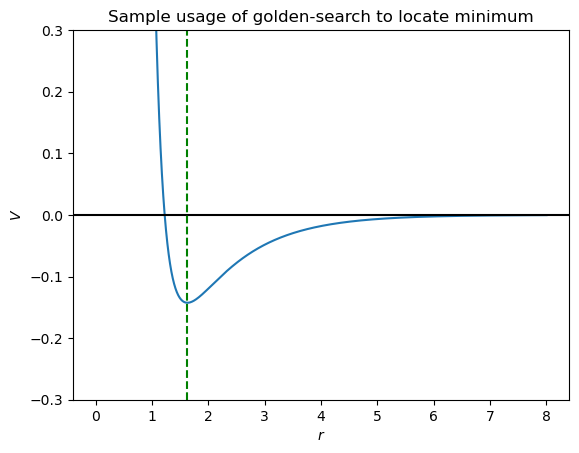

In [10]:
sigma = 1

def V(r, V0=1):
    return V0 * ((sigma / r)**6 - np.exp(-r/sigma))

rlist = np.linspace(1e-3, 8, 1000)
rmin = golden(V, 1.1, 2, kmax=200, tol=1e-8)
plt.plot(rlist, V(rlist))
plt.ylim(-.3, .3)
plt.axhline(0, c='k')
plt.axvline(rmin, c='g', ls='--')
plt.xlabel(r'$r$')
plt.ylabel(r'$V$')
plt.title('Sample usage of golden-search to locate minimum')
plt.show()

### Gradient descent (minimization tool)

In [11]:
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad

def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews

Converged at iteration 50


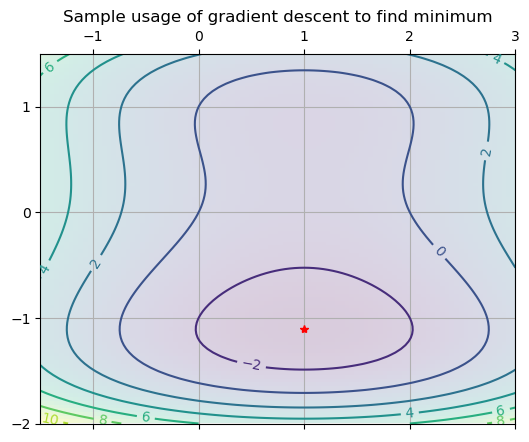

In [12]:
def sample_phi(xs):
    x0, x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x = np.linspace(-1.5, 3.0, 100)
y = np.linspace(-2, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = sample_phi(np.array([X, Y]))

xolds = np.array([2.,0.25])
xnews = descent(sample_phi, gradient, xolds)

fig, ax = plt.subplots(dpi=100)

my_extent = [min(x), max(x), min(y), max(y)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
ax.plot(*xnews, 'r*')
ax.set_title("Sample usage of gradient descent to find minimum")
csx = ax.contour(X, Y, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')


fig.show()

### Powell's algorithm (minimization tool)

In [13]:
def powell(phi,xolds,nreset=4,cycmax=200,tol=1.e-8):
    n = xolds.size
    for icyc in range(cycmax):
        xnews = np.copy(xolds)
    
        if icyc%nreset==0:
            U = np.identity(n)
        for k in range(n):
            ga = golden(lambda g: phi(xnews+g*U[:,k]),-10.,+10.)
            xnews += ga*U[:,k]
        U[:,:-1] = U[:,1:]
        U[:,-1] = xnews - xolds
        ga = golden(lambda g: phi(xolds+g*U[:,-1]),-10.,+10.)
        xolds += ga*U[:,-1]
        
        err = termcrit(xolds,xnews)
        # print(icyc, xnews, err, phi(xnews))
        if err < tol:
            break
    else:
        xnews = None
    return xnews

[ 1.00000002 -1.10715988]


Text(0.5, 1.0, "Sample usage of powell's algorithm to find minimum")

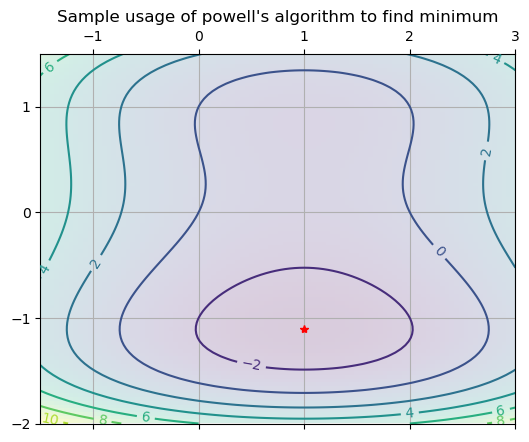

In [14]:
def phi_func(xs):
    x0,x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x0 = np.linspace(-1.5, 3.0, 100)
x1 = np.linspace(-2, 1.5, 100)
X0, X1 = np.meshgrid(x, y)
output = phi_func(np.array([X0, X1]))

fig, ax = plt.subplots(1, 1, dpi=100)

xolds = np.array([2.,0.25])
xnews = powell(sample_phi, xolds); print(xnews)
ax.plot(*xnews, 'r*')

my_extent = [min(x0), max(x0), min(x1), max(x1)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
csx = ax.contour(X0, X1, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')
ax.set_title("Sample usage of powell's algorithm to find minimum")

### Plotting subplots

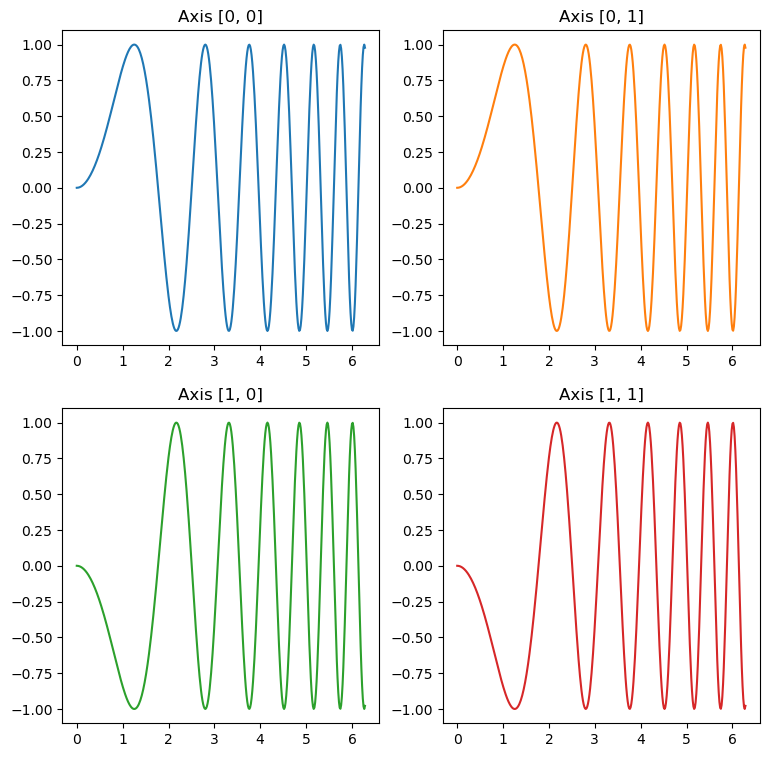

In [15]:
#sample incomplete 2 by 2 plot 

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x, y)
axs[0, 0].set_title('Axis [0, 0]')

axs[0, 1].plot(x, y, 'tab:orange')
axs[0, 1].set_title('Axis [0, 1]')

axs[1, 0].plot(x, -y, 'tab:green')
axs[1, 0].set_title('Axis [1, 0]')

axs[1, 1].plot(x, -y, 'tab:red')
axs[1, 1].set_title('Axis [1, 1]')

fig.show()

### Others

(Optional) Visualizing the vector field.
This is not required to get the method running, but it's a nice way for us to realize that we are indeed working with vector fields. Also, the mesh-forming syntax here will be useful for our succeeding activities.

In [16]:
def nonlin_func(x):
    # From Eq. 5.72 in Gezerlis, annotating Code 5.5
    #* Note: we expect the input and output of the function
    #  to be BOTH vectors. If x is a k-dimensional vector,
    #  then f(x) should also return a k-dimensional vector.  
    x0, x1 = x[0], x[1]

    # This is the same as defining f0 and f1 separately. We
    # just casted the output directly into the array
    return np.array([
        (x0**2) - (2*x0) + (x1**4) - (2*x1**2) + (x1),
        (x0**2) + (x0) + (2*x1**3) - (2*x1**2) - (1.5*x1) - 0.05   
    ])

x_test = np.array([0.5, 0.6])
print(nonlin_func(x_test))

[-0.7404 -0.488 ]


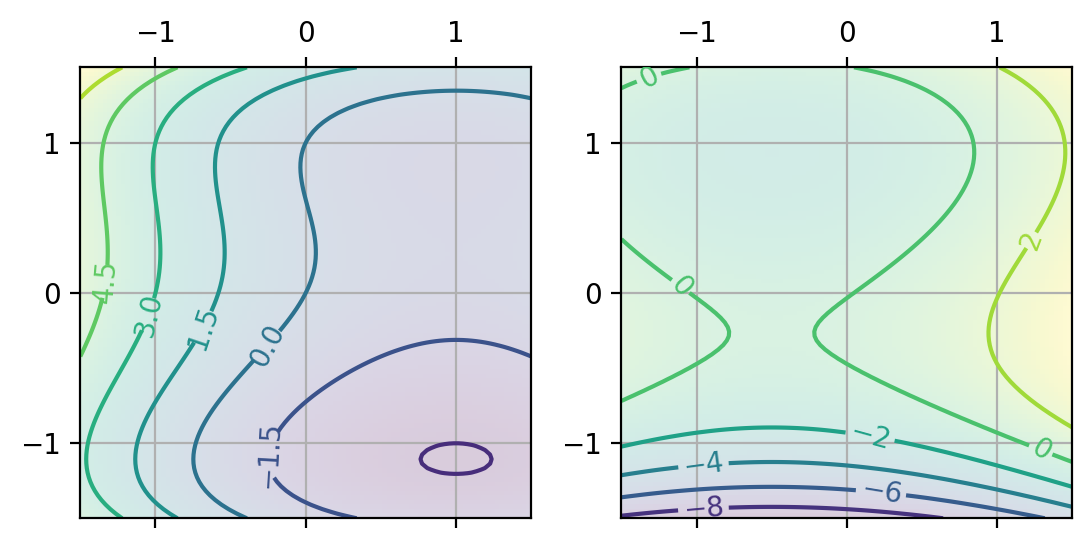

In [17]:
x = np.linspace(-1.5, 1.5, 100)
y = np.linspace(-1.5, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, axs = plt.subplots(1, 2, dpi=200)

my_extent = [min(x), max(x), min(y), max(y)]
axs[0].matshow(output[0], origin="lower", extent=my_extent, alpha=0.2)
csx = axs[0].contour(X, Y, output[0])
axs[0].clabel(csx)

axs[1].matshow(output[1], origin="lower", extent=my_extent, alpha=0.2)
csy = axs[1].contour(X, Y, output[1])
axs[1].clabel(csy)

for ax in axs:
    ax.grid(True)

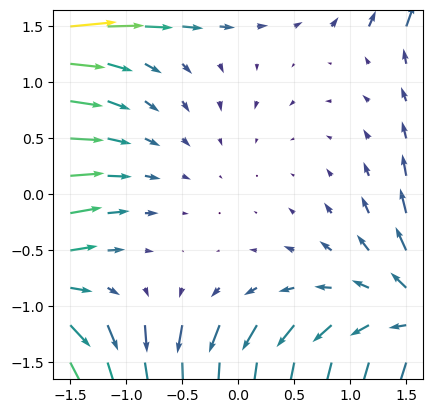

In [18]:
x = np.linspace(-1.5, 1.5, 10)
y = np.linspace(-1.5, 1.5, 10)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, ax = plt.subplots(1, dpi=100)

mag = np.sqrt(output[0]**2 + np.sqrt(output[1]**2))
ax.quiver(X, Y, output[0], output[1], mag)
ax.grid(alpha=0.2)
ax.set_aspect("equal")

In [19]:
import numpy as np

def backsub(U,bs):
    """
    Input:
        * U matrix
        * bs known vector
    Output: solve column vector using back substitution
    """
    n = bs.size
    xs = np.zeros(n)
    for i in reversed(range(n)):
        xs[i] = (bs[i] - U[i,i+1:]@xs[i+1:])/U[i,i]
    return xs

def gauelimpivot(inA,inbs):
    """
    Input:
        * inA matrix
        * inbs known vector
    Output: solve column vector with gaussian elimination
    """
    A = np.copy(inA)
    bs = np.copy(inbs)
    n = bs.size
    for j in range(n-1):
        k = np.argmax(np.abs(A[j:,j])) + j
        if k != j:
            A[j,:], A[k,:] = A[k,:], A[j,:].copy()
            bs[j], bs[k] = bs[k], bs[j]
    
        for i in range(j+1,n):
            coeff = A[i,j]/A[j,j]
            A[i,j:] -= coeff*A[j,j:]
            bs[i] -= coeff*bs[j]
            
    xs = backsub(A,bs)
    return xs

def termcrit(xolds,xnews):
    """
    Input:
        * xolds older estimates
        * xnews newest estimates
    Output: solve termination criterion with numpy
    """
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def fs(xs):
    """
    Input:
        * xs tuple input
    Output: scalar outputs from two functions given one set of input
    """
    x0, x1 = xs
    f0 = x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1
    f1 = x0**2 + x0 + 2*x1**3 - 2*x1**2 - 1.5*x1 - 0.05
    return np.array([f0,f1])

def jacobian(fs,xs,h=1.e-4):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * xs : 1d array representing the eval point
        * h : float, optional 
    
    Output: builds jacobian matrix Jf and array containing values evaluated at xs
    """
    n = xs.size
    iden = np.identity(n)
    Jf = np.zeros((n,n))
    fs0 = fs(xs)
    for j in range(n):
        fs1 = fs(xs+iden[:,j]*h)
        Jf[:,j] = (fs1 - fs0)/h
    return Jf, fs0

def multinewton(fs,jacobian,xolds,kmax=200,tol=1.e-8):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * jacobian : calcs the jacobian
        * xolds : 1d array containing the initial guess vector
        * kmax : no of iterations
        * tol : tolerance for convergence
    
    Output: 1d array of the approximate root vector if converged
    """
    for k in range(1,kmax):
        Jf, fsxolds = jacobian(fs, xolds)
        xnews = xolds + gauelimpivot(Jf, -fsxolds)
        err = termcrit(xolds, xnews)
        print(k, xnews, err)
        if err < tol:
            break
        
        xolds = np.copy(xnews)
    else:
        xnews = None
    return xnews

if __name__ == '__main__':
    xolds = np.array([1.,1.])
    xnews = multinewton(fs, jacobian, xolds)
    print(xnews); print(fs(xnews))

1 [0.68327197 1.99963178] 0.9634539886260238
2 [0.38286992 1.62816875] 1.0127537609121247
3 [0.56358881 1.4144802 ] 0.4717294772974023
4 [0.5900614  1.32693341] 0.11084089956296016
5 [0.59215596 1.3126421 ] 0.014424613090514531
6 [0.59218625 1.31228241] 0.00032525133774643014
7 [0.59218627 1.31228212] 2.5249741194196077e-07
8 [0.59218627 1.31228212] 4.335881037833639e-11
[0.59218627 1.31228212]
[3.97459843e-14 2.77972090e-14]
